# 04 · Logistic Regression held-out evaluation

This notebook loads the exported Logistic Regression pipeline and evaluates it once on the untouched stratified test partition. **It does not fit or retrain a model.** It recreates the saved split using the same seed and stratification recipe from Notebook 3, then checks that the loaded artifact accepts the expected 30 features and returns predictions before calculating test metrics.

**Primary metric:** malignant-class recall. Secondary metrics: precision, F1, specificity, accuracy, balanced accuracy, and ROC-AUC. The test result is a final internal estimate for this split, not evidence of clinical readiness or external generalization.

In [11]:
from pathlib import Path
import json
import math
from statistics import NormalDist

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split

SEED = 42
TARGET = 'diagnosis'
ID_COLUMN = 'id'
LABEL_TO_INT = {'B': 0, 'M': 1}
POSITIVE_LABEL = 1
cwd = Path.cwd().resolve()
REPO_ROOT = next((candidate for candidate in [cwd, *cwd.parents]
                  if (candidate / 'data/raw/Raw_Breast_Cancer_Data.csv').exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate repository data/raw/Raw_Breast_Cancer_Data.csv from the notebook working directory.')
DATA_PATH = REPO_ROOT / 'data/raw/Raw_Breast_Cancer_Data.csv'
MODEL_DIR = REPO_ROOT / 'models/Logistic_Regression'
REPORT_DIR = REPO_ROOT / 'reports/figures/Logistic_Regression'
MODEL_PATH = MODEL_DIR / 'logistic_regression_pipeline.joblib'
METADATA_PATH = REPORT_DIR / 'model_metadata.json'
print(f'Python package environment: scikit-learn {sklearn.__version__}')
print('Model artifact:', MODEL_PATH)

Python package environment: scikit-learn 1.9.0
Model artifact: C:\Projects_Tracking\Breast_Cancer_Prediction\models\Logistic_Regression\logistic_regression_pipeline.joblib


In [12]:
if not MODEL_PATH.exists() or not METADATA_PATH.exists():
    raise FileNotFoundError('Run Notebook 3 first and confirm its pipeline and metadata artifacts are present.')
metadata = json.loads(METADATA_PATH.read_text(encoding='utf-8'))
if metadata.get('model') != 'LogisticRegression':
    raise ValueError('The metadata does not describe the expected Logistic Regression model.')
if metadata.get('seed') != SEED or metadata.get('target') != TARGET:
    raise ValueError('Notebook 3 metadata does not match the expected target or split seed.')

raw_df = pd.read_csv(DATA_PATH)
empty_columns = raw_df.columns[raw_df.isna().all()].tolist()
df = raw_df.drop(columns=empty_columns).copy()
y = df[TARGET].map(LABEL_TO_INT)
if y.isna().any() or set(y.unique()) != {0, 1}:
    raise ValueError('Unexpected target labels; stop and inspect the dataset.')
feature_names = metadata['features']
if feature_names != [c for c in df.columns if c not in [TARGET, ID_COLUMN]]:
    raise ValueError('Dataset feature columns/order differ from the model metadata.')
X = df[feature_names]

# Reproduce Notebook 3's split indices exactly; no fitting occurs here.
all_idx = np.arange(len(y))
dev_idx, test_idx = train_test_split(
    all_idx, test_size=0.20, random_state=SEED, stratify=y)
train_idx, val_idx = train_test_split(
    dev_idx, test_size=0.25, random_state=SEED, stratify=y.iloc[dev_idx])
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
print(f'Test records: {len(test_idx)}')
print('Test class counts:', y_test.value_counts().sort_index().rename(index={0: 'B (benign)', 1: 'M (malignant)'}).to_dict())
print('Test partition matches saved metadata:', len(test_idx) == metadata['split_sizes']['test'])

Test records: 114
Test class counts: {'B (benign)': 72, 'M (malignant)': 42}
Test partition matches saved metadata: True


In [13]:
# Load-only sanity check: no fit/fit_transform call is made in this notebook.
model = joblib.load(MODEL_PATH)
if not hasattr(model, 'predict') or not hasattr(model, 'predict_proba'):
    raise TypeError('Loaded artifact is not a prediction pipeline with probability support.')
if list(model.feature_names_in_) != feature_names:
    raise ValueError('Loaded model feature order differs from metadata.')
y_pred = model.predict(X_test)
y_score = model.predict_proba(X_test)[:, list(model.classes_).index(POSITIVE_LABEL)]
if len(y_pred) != len(y_test) or not np.isfinite(y_score).all():
    raise ValueError('Loaded model did not produce valid predictions for every test row.')
print('Load and prediction sanity check passed.')
print('Predictions:', len(y_pred), '| positive-class probability range:',
      (round(float(y_score.min()), 4), round(float(y_score.max()), 4)))

Load and prediction sanity check passed.
Predictions: 114 | positive-class probability range: (0.0001, 1.0)


## Held-out test metrics

The positive class is malignant (`M`, encoded as 1). Specificity measures the fraction of benign cases correctly identified. The recall interval below is a Wilson 95% binomial interval to show sampling uncertainty for the test set's malignant cases; it does not account for dataset shift.

,held-out test result
malignant_recall (primary),0.976190
precision,1.000000
F1,0.987952
specificity,1.000000
accuracy,0.991228
balanced_accuracy,0.988095
ROC-AUC,0.997685
true_negatives,72.000000
false_positives,0.000000
false_negatives,1.000000


Classification report (0=benign, 1=malignant):
               precision    recall  f1-score   support

   Benign (B)       0.99      1.00      0.99        72
Malignant (M)       1.00      0.98      0.99        42

     accuracy                           0.99       114
    macro avg       0.99      0.99      0.99       114
 weighted avg       0.99      0.99      0.99       114



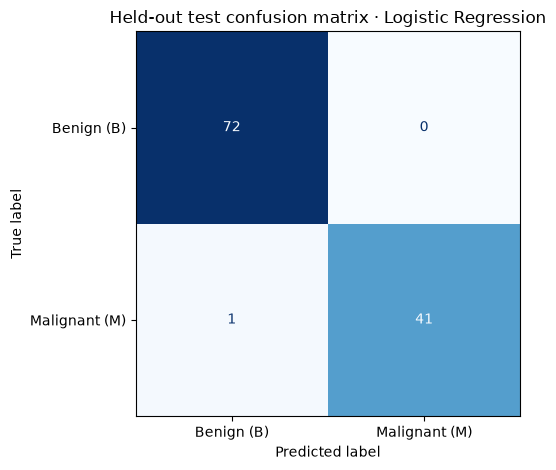

In [14]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
test_metrics = {
    'malignant_recall (primary)': recall_score(y_test, y_pred, pos_label=1, zero_division=0),
    'precision': precision_score(y_test, y_pred, pos_label=1, zero_division=0),
    'F1': f1_score(y_test, y_pred, pos_label=1, zero_division=0),
    'specificity': tn / (tn + fp) if (tn + fp) else np.nan,
    'accuracy': accuracy_score(y_test, y_pred),
    'balanced_accuracy': balanced_accuracy_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_score),
    'true_negatives': int(tn), 'false_positives': int(fp),
    'false_negatives': int(fn), 'true_positives': int(tp),
}

def wilson_interval(successes, trials, confidence=0.95):
    if trials == 0:
        return (np.nan, np.nan)
    z = NormalDist().inv_cdf(1 - (1 - confidence) / 2)
    p_hat = successes / trials
    denom = 1 + z*z/trials
    center = (p_hat + z*z/(2*trials)) / denom
    half = z * math.sqrt(p_hat*(1-p_hat)/trials + z*z/(4*trials*trials)) / denom
    return center-half, center+half

recall_ci = wilson_interval(tp, tp + fn)
test_metrics['malignant_recall_Wilson_95%_low'] = recall_ci[0]
test_metrics['malignant_recall_Wilson_95%_high'] = recall_ci[1]
display(pd.Series(test_metrics, name='held-out test result').to_frame())
print('Classification report (0=benign, 1=malignant):')
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=['Benign (B)', 'Malignant (M)'], zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1], display_labels=['Benign (B)', 'Malignant (M)'],
    cmap='Blues', colorbar=False)
plt.title('Held-out test confusion matrix · Logistic Regression')
plt.tight_layout()
plt.show()

## Error analysis

Review false negatives first because malignant recall is the declared primary metric. The table identifies records by source `id`, which was excluded from model inputs. Probability values are model scores, not calibrated clinical risk estimates.

In [15]:
test_results = pd.DataFrame({
    'source_id': df.iloc[test_idx][ID_COLUMN].to_numpy(),
    'actual': pd.Series(y_test.to_numpy()).map({0: 'B', 1: 'M'}),
    'predicted': pd.Series(y_pred).map({0: 'B', 1: 'M'}),
    'malignant_probability': y_score,
})
test_results['error_type'] = np.select(
    [(test_results.actual == 'M') & (test_results.predicted == 'B'),
     (test_results.actual == 'B') & (test_results.predicted == 'M')],
    ['false_negative', 'false_positive'], default='correct')
errors = test_results[test_results.error_type != 'correct'].sort_values('malignant_probability')
print('Test error counts:', test_results.error_type.value_counts().to_dict())
print('Misclassified test records:')
display(errors.reset_index(drop=True))

Test error counts: {'correct': 113, 'false_negative': 1}
Misclassified test records:


,source_id,actual,predicted,malignant_probability,error_type
0,859983,M,B,0.215975,false_negative


## Test results, limitations, and conclusion

The loaded pipeline passed the prediction sanity check and evaluated **114 held-out records** (72 benign, 42 malignant) without retraining. It produced **0.9762 malignant recall** (41/42), **1.0000 precision**, **0.9880 F1**, **1.0000 specificity**, **0.9912 accuracy**, **0.9881 balanced accuracy**, and **0.9977 ROC-AUC**. The confusion matrix had 72 true negatives, 0 false positives, 1 false negative, and 41 true positives. The Wilson 95% interval for malignant recall is **0.8768–0.9958**, reflecting uncertainty from only 42 malignant test cases.

The one false negative was source record `859983` (actual malignant, predicted benign) with malignant probability **0.2160**. This score is not a calibrated clinical risk estimate. The test metrics are slightly higher than the validation metrics in Notebook 3 (validation recall 0.9535, precision 0.9535, F1 0.9535, accuracy 0.9649, ROC-AUC 0.9954). This is an observed split difference, not evidence the model generalizes better than expected; the test set was used once and not for tuning.

**Conclusion:** the saved Logistic Regression pipeline performed strongly on this held-out partition under the predeclared recall-first criterion. It is an internal result for this dataset only, not clinical validation, deployment approval, or evidence of performance on new populations.

**Limitations:** the test partition contains only 114 records, including 42 malignant cases, so a single additional missed malignant case would materially change recall. The recall confidence interval is broad at its lower end. Train, validation, and test all come from the same curated dataset; no independent institution, acquisition site, demographic, or clinical context is available to assess distribution shift or subgroup performance. Correlated predictors also limit coefficient-level interpretation. Do not present these results as a diagnostic tool or clinical performance claim.

### Self-critique

The strongest objection is that 41/42 malignant cases correctly identified can look nearly definitive, while its uncertainty interval and same-source split show how little evidence the test set provides about performance elsewhere. We report the interval, the single false negative, the validation comparison, and the lack of external validation; these make the limits visible but cannot substitute for a larger independent cohort.